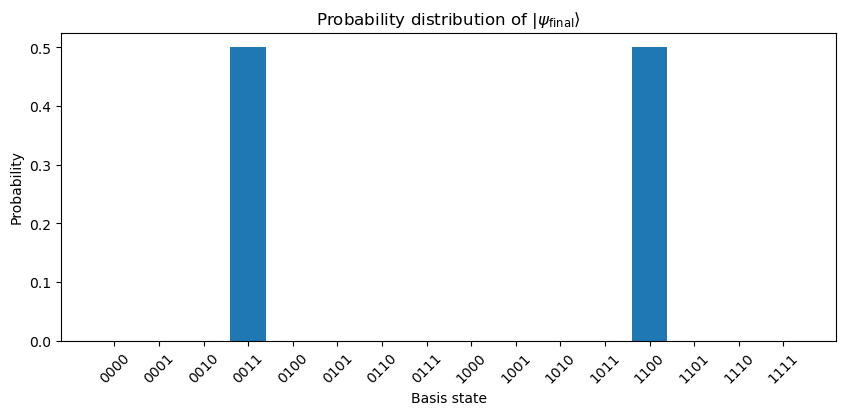

In [2]:
import matplotlib.pyplot as plt 
import numpy as np
from IPython.display import Image 
from qutip import (Qobj, about, basis, coherent, coherent_dm, create, destroy, expect, fock, fock_dm, mesolve, 
                   qeye, sigmax, sigmay, sigmaz, tensor, thermal_dm, anim_matrix_histogram, anim_fock_distribution)
from matplotlib import rc
rc('animation', html='jshtml')
%matplotlib inline

P_0= 0.5*(qeye(2)+sigmaz())
P_1= 0.5*(qeye(2)-sigmaz())
Q_0= 0.5*(sigmax()+1j*sigmay())
Q_1= 0.5*(sigmax()-1j*sigmay())

dag= tensor(P_0,Q_1)+ np.sqrt(2)* tensor(Q_1,P_1)
nor= tensor(P_0,Q_0)+ np.sqrt(2)* tensor(Q_0,P_1)

a_dag= tensor (dag,qeye(2),qeye(2))
a=tensor (nor,qeye(2),qeye(2))

b_dag= tensor(qeye(2),qeye(2), dag)
b= tensor(qeye(2),qeye(2), nor)

H=(np.pi/4)*(b_dag*a + b*a_dag)

U_B= (1j*H).expm()

vac = tensor(basis(2,0), basis(2,0))
one = tensor(basis(2,0), basis(2,1))
two = tensor(basis(2,1), basis(2,1))


psi0= tensor(one,one)

psi_final=U_B * psi0

#print("psi_final=",psi_final)

amps = psi_final.full().flatten()

probs = np.abs(amps)**2

labels = [format(i, '04b') for i in range(len(probs))]
plt.figure(figsize=(10,4))
plt.bar(labels, probs)
plt.xlabel("Basis state")
plt.ylabel("Probability")
plt.title(r"Probability distribution of $|\psi_{\rm final}\rangle$")
plt.xticks(rotation=45)
plt.show()

In [6]:
a_dag

Quantum object: dims=[[2, 2, 2, 2], [2, 2, 2, 2]], shape=(16, 16), type='oper', dtype=CSR, isherm=False
Qobj data =
[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         1.         0.         0.         0. 

In [7]:
a

Quantum object: dims=[[2, 2, 2, 2], [2, 2, 2, 2]], shape=(16, 16), type='oper', dtype=CSR, isherm=False
Qobj data =
[[0.         0.         0.         0.         1.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         1.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  1.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         1.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  1.41421356 0.         0.         0.        ]
 [0.         0.         0.         0.         0. 

In [8]:
b_dag

Quantum object: dims=[[2, 2, 2, 2], [2, 2, 2, 2]], shape=(16, 16), type='oper', dtype=CSR, isherm=False
Qobj data =
[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         1.41421356 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         1. 

In [9]:
b

Quantum object: dims=[[2, 2, 2, 2], [2, 2, 2, 2]], shape=(16, 16), type='oper', dtype=CSR, isherm=False
Qobj data =
[[0.         1.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         1.41421356 0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         1.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0. 

In [10]:
H

Quantum object: dims=[[2, 2, 2, 2], [2, 2, 2, 2]], shape=(16, 16), type='oper', dtype=CSR, isherm=True
Qobj data =
[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.78539816 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         1.11072073
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.78539816 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         1.11072

In [11]:
U_B

Quantum object: dims=[[2, 2, 2, 2], [2, 2, 2, 2]], shape=(16, 16), type='oper', dtype=Dense, isherm=False
Qobj data =
[[ 1.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j          7.07106781e-01+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.70710678j  0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j          0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j          0.00000000e+00+0.j
   1.00000000e

In [12]:
vac

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[1.]
 [0.]
 [0.]
 [0.]]

In [13]:
one

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]]

In [14]:
two

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 [1.]]